In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
set_font_size(FONT_SIZE)

## Procedure
![Example Setup](outputs/surface_tracking/setup.png)

1. Follow the setup in the image
2. Align the robot with the obstacle
3. Change the desired final goal reference position in the config file -> go_x = ...
4. Change k to the desired value either in the config or in GUI and then launch python3 MultiVMC_MovingGoal_Pub.py only once python3 GUI_MultiVMC_Torque.py has said "VMCTorqueNode started — 1 virtual component(s), control @ 330 Hz"

Make sure not to publish any reference positions from the GUI only  MultiVMC_MovingGoal_Pub.py will be publishing to the /VC_ref_pos topic

# Surface Tracking: X-Y Trajectory Comparison

Analysis of robot end-effector position in the x-y plane during surface tracking with obstacle avoidance.

**Setup:**
- Moving reference in x-direction (0 → 0.4 m)
- Slanted obstacle along x-axis causing trajectory deviation
- Test for spring stiffness values: k ∈ {25, 50, 75, 100, 200} N/m
- Cutoff: reference position reaches x = 0.4 m

**Goal:** Visualize how different spring constants affect tracking accuracy and obstacle response in the x-y plane.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import os

# Load all npz files
k_values = [15, 25, 50, 75, 100, 200]
data = {}

for k in k_values:
    fname = os.path.join('outputs', 'surface_tracking', f'k{k}.npz')
    try:
        d = np.load(fname)
        data[k] = d
        print(f"Loaded {fname}: {len(d['t'])} samples")
    except FileNotFoundError:
        print(f"Warning: {fname} not found")

print(f"\nLoaded {len(data)} k values: {list(data.keys())}")

Loaded outputs/surface_tracking/k15.npz: 30575 samples
Loaded outputs/surface_tracking/k25.npz: 24719 samples
Loaded outputs/surface_tracking/k50.npz: 17447 samples
Loaded outputs/surface_tracking/k75.npz: 15409 samples
Loaded outputs/surface_tracking/k100.npz: 18275 samples
Loaded outputs/surface_tracking/k200.npz: 20399 samples

Loaded 6 k values: [15, 25, 50, 75, 100, 200]


In [3]:
# ═══════════════════════════════════════════════════════════════════════════════
# MANUAL SLIP EVENT TUNING - Adjust times below to match your observations
# ═══════════════════════════════════════════════════════════════════════════════
slip_event_times = {
    15: 84.3,    # [s] Time when k=15 slips past obstacle
    25: 42.0,    # [s] Time when k=25 slips past obstacle
    50: 32.0,    # [s] Time when k=50 slips past obstacle
    75: 33.2,    # [s] Time when k=75 slips past obstacle
    100: 33.5,   # [s] Time when k=100 slips past obstacle
    200: 25.4,   # [s] Time when k=200 slips past obstacle
}
# ═══════════════════════════════════════════════════════════════════════════════

# Extract trajectories - NO CUTOFF, use all available data
trajectories = {}

for k in sorted(data.keys()):
    d = data[k]
    t = d['t']
    comp_pos = d['comp_pos']  # (n, N_VC, 3)
    goal = d['goal']          # (n, N_VC, 3)
    
    # Use all data (NO x = 0.4 cutoff)
    idx_cutoff = len(t)
    
    # Extract all data
    ee_pos = comp_pos[:idx_cutoff, 0, :2]   # (n, 2) end-effector x,y
    ref_pos = goal[:idx_cutoff, 0, :2]      # (n, 2) reference x,y
    ee_y = comp_pos[:idx_cutoff, 0, 1]      # (n,) y position
    
    # Get slip time from manual tuning parameter
    slip_time_manual = slip_event_times.get(k, 0.0)
    t_cut = t[:idx_cutoff]
    t_rel = t_cut - t_cut[0]
    
    # Find closest index to manual slip time
    slip_idx = np.argmin(np.abs(t_rel - slip_time_manual))
    slip_time = t[slip_idx]
    slip_magnitude = ee_y[slip_idx]
    
    # Normalize y values to [-1, 1] based on min/max
    y_min = ee_y.min()
    y_max = ee_y.max()
    y_range = y_max - y_min
    if y_range > 1e-6:
        ee_pos_norm = ee_pos.copy()
        ee_pos_norm[:, 1] = 2 * (ee_y - y_min) / y_range - 1  # Normalize to [-1, 1]
        ref_pos_norm = ref_pos.copy()
        ref_pos_norm[:, 1] = 2 * (ref_pos[:, 1] - y_min) / y_range - 1
    else:
        ee_pos_norm = ee_pos.copy()
        ref_pos_norm = ref_pos.copy()
    
    trajectories[k] = {
        'ee_xy': ee_pos,
        'ref_xy': ref_pos,
        'ee_xy_norm': ee_pos_norm,      # Normalized y to [-1, 1]
        'ref_xy_norm': ref_pos_norm,
        'cutoff_idx': idx_cutoff,
        'duration': t[idx_cutoff - 1] - t[0],
        'slip_event_idx': slip_idx,
        'slip_time': slip_time_manual,  # Use manual time
        'slip_magnitude': slip_magnitude,
        'y_min': y_min,
        'y_max': y_max,
    }
    
    print(f"k={k:>3d}: {idx_cutoff:>5d} samples ({trajectories[k]['duration']:.2f}s) | Slip @ t={slip_time_manual:>6.2f}s (y={slip_magnitude:>9.6f}m)")

k= 15: 30575 samples (92.65s) | Slip @ t= 84.30s (y=-0.001412m)
k= 25: 24719 samples (74.90s) | Slip @ t= 42.00s (y=-0.001358m)
k= 50: 17447 samples (52.87s) | Slip @ t= 32.00s (y=-0.001451m)
k= 75: 15409 samples (46.69s) | Slip @ t= 33.20s (y=-0.001381m)
k=100: 18275 samples (55.38s) | Slip @ t= 33.50s (y= 0.000086m)
k=200: 20399 samples (61.82s) | Slip @ t= 25.40s (y=-0.000895m)


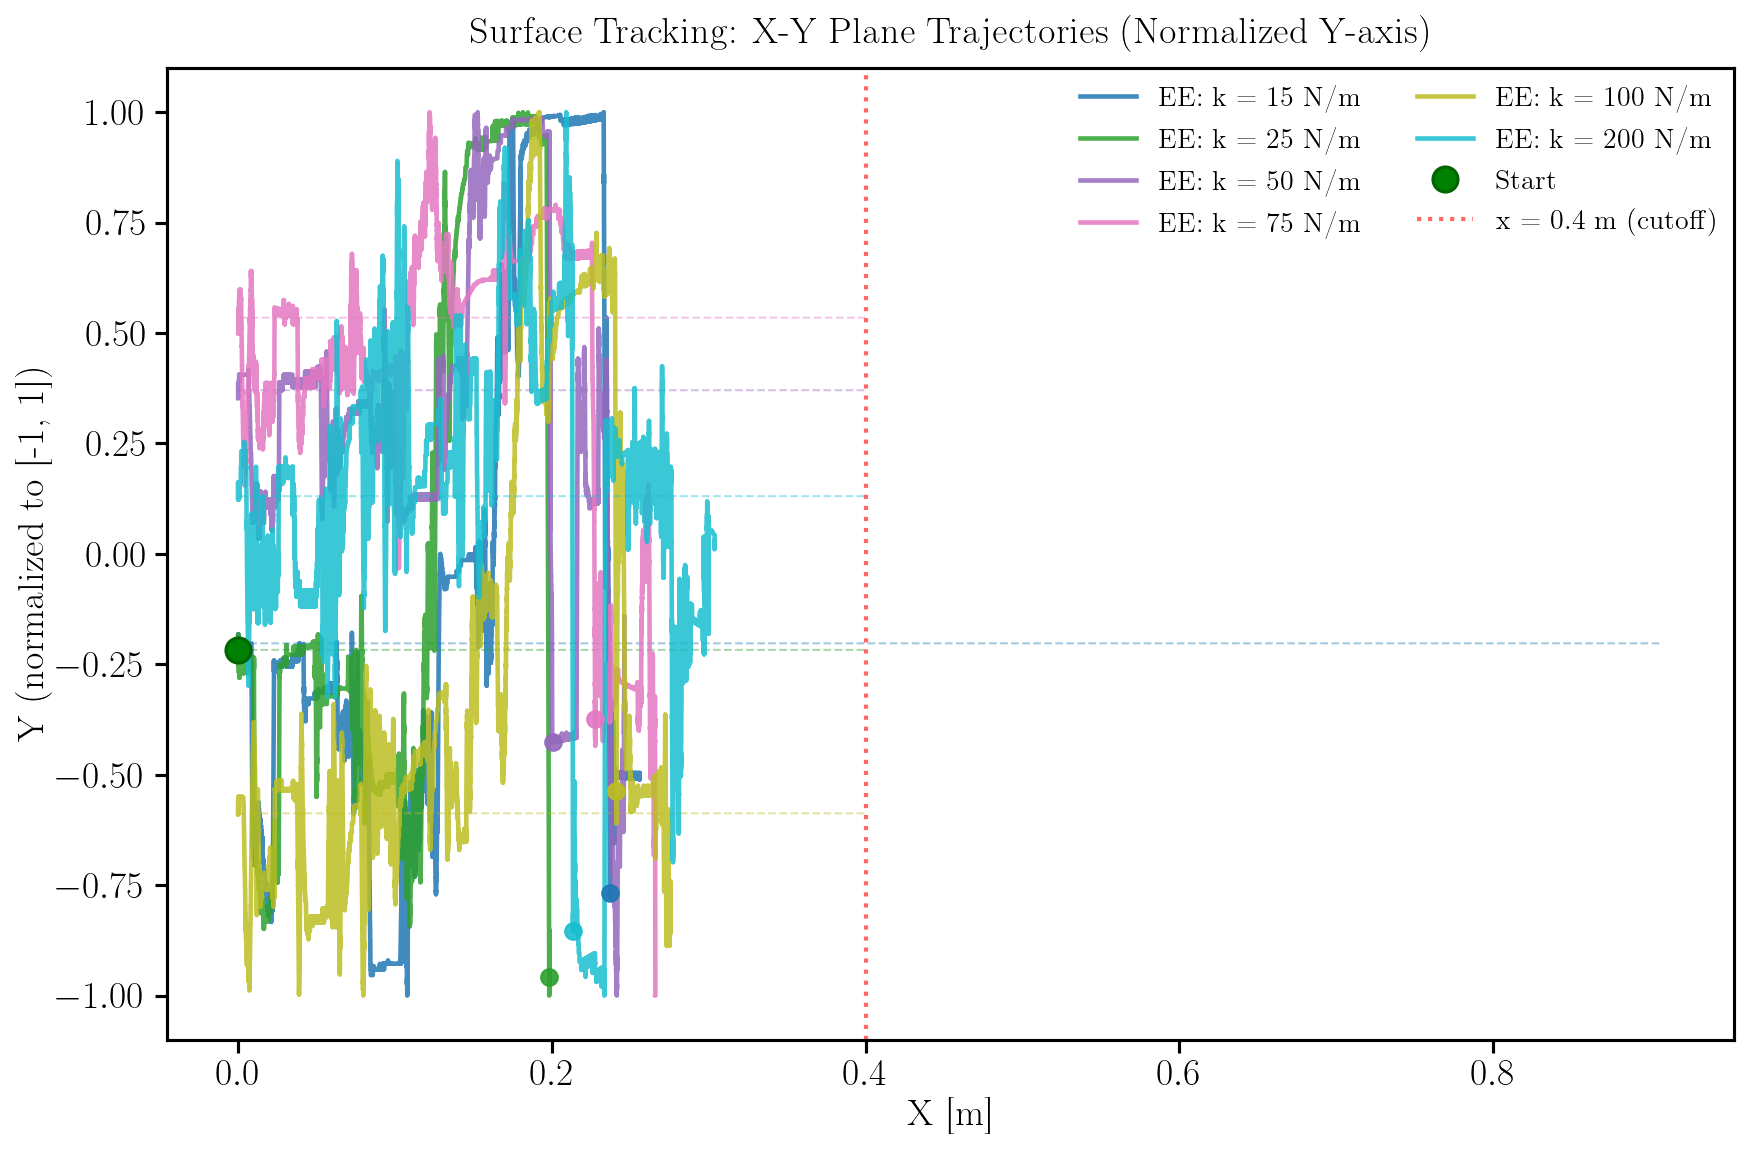


✓ X-Y plot complete (y-axis normalized to [-1, 1])
  Solid lines = end-effector trajectory
  Dashed lines = reference trajectory
  Dots = obstacle slip event (steepest falling edge in y)


In [4]:
# Plot: X-Y plane trajectory comparison (with normalized y-axis)
fig, ax = plt.subplots(figsize=(12, 8))

# Color map for k values
colors = plt.cm.tab10(np.linspace(0, 1, len(trajectories)))
color_map = {k: colors[i] for i, k in enumerate(sorted(trajectories.keys()))}

# Plot trajectories
for k in sorted(trajectories.keys()):
    traj = trajectories[k]
    ee_xy_norm = traj['ee_xy_norm']   # Normalized x,y (y is [-1, 1])
    ref_xy_norm = traj['ref_xy_norm']
    slip_idx = traj['slip_event_idx']
    
    # End-effector trajectory (solid)
    ax.plot(ee_xy_norm[:, 0], ee_xy_norm[:, 1], 
            color=color_map[k], linewidth=2.2, alpha=0.85,
            label=f'EE: k = {k} N/m')
    
    # Reference trajectory (dashed, lighter)
    ax.plot(ref_xy_norm[:, 0], ref_xy_norm[:, 1], 
            '--', color=color_map[k], linewidth=1.0, alpha=0.4)
    
    # Mark slip event
    if slip_idx < len(ee_xy_norm):
        ax.plot(ee_xy_norm[slip_idx, 0], ee_xy_norm[slip_idx, 1],
                'o', color=color_map[k], markersize=8, alpha=0.9, zorder=4)

# Start point
start_ee = trajectories[25]['ee_xy_norm'][0]
ax.plot(start_ee[0], start_ee[1], 'go', markersize=12, label='Start', zorder=5, markeredgewidth=1.5, markeredgecolor='darkgreen')

# Cutoff line at x = 0.4
ax.axvline(x=0.4, color='red', linestyle=':', linewidth=2.0, alpha=0.6, label='x = 0.4 m (cutoff)')

ax.set_xlabel('X [m]')
ax.set_ylabel('Y (normalized to [-1, 1])')
ax.set_title('Surface Tracking: X-Y Plane Trajectories (Normalized Y-axis)')
ax.set_ylim(-1.1, 1.1)
ax.legend(loc='best', framealpha=0.95, ncol=2)
ax.grid(GRID)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'surface_tracking', 'xy_trajectory_comparison.pdf'))
plt.show()

print("\n✓ X-Y plot complete (y-axis normalized to [-1, 1])")
print("  Solid lines = end-effector trajectory")
print("  Dashed lines = reference trajectory")
print("  Dots = obstacle slip event (steepest falling edge in y)")

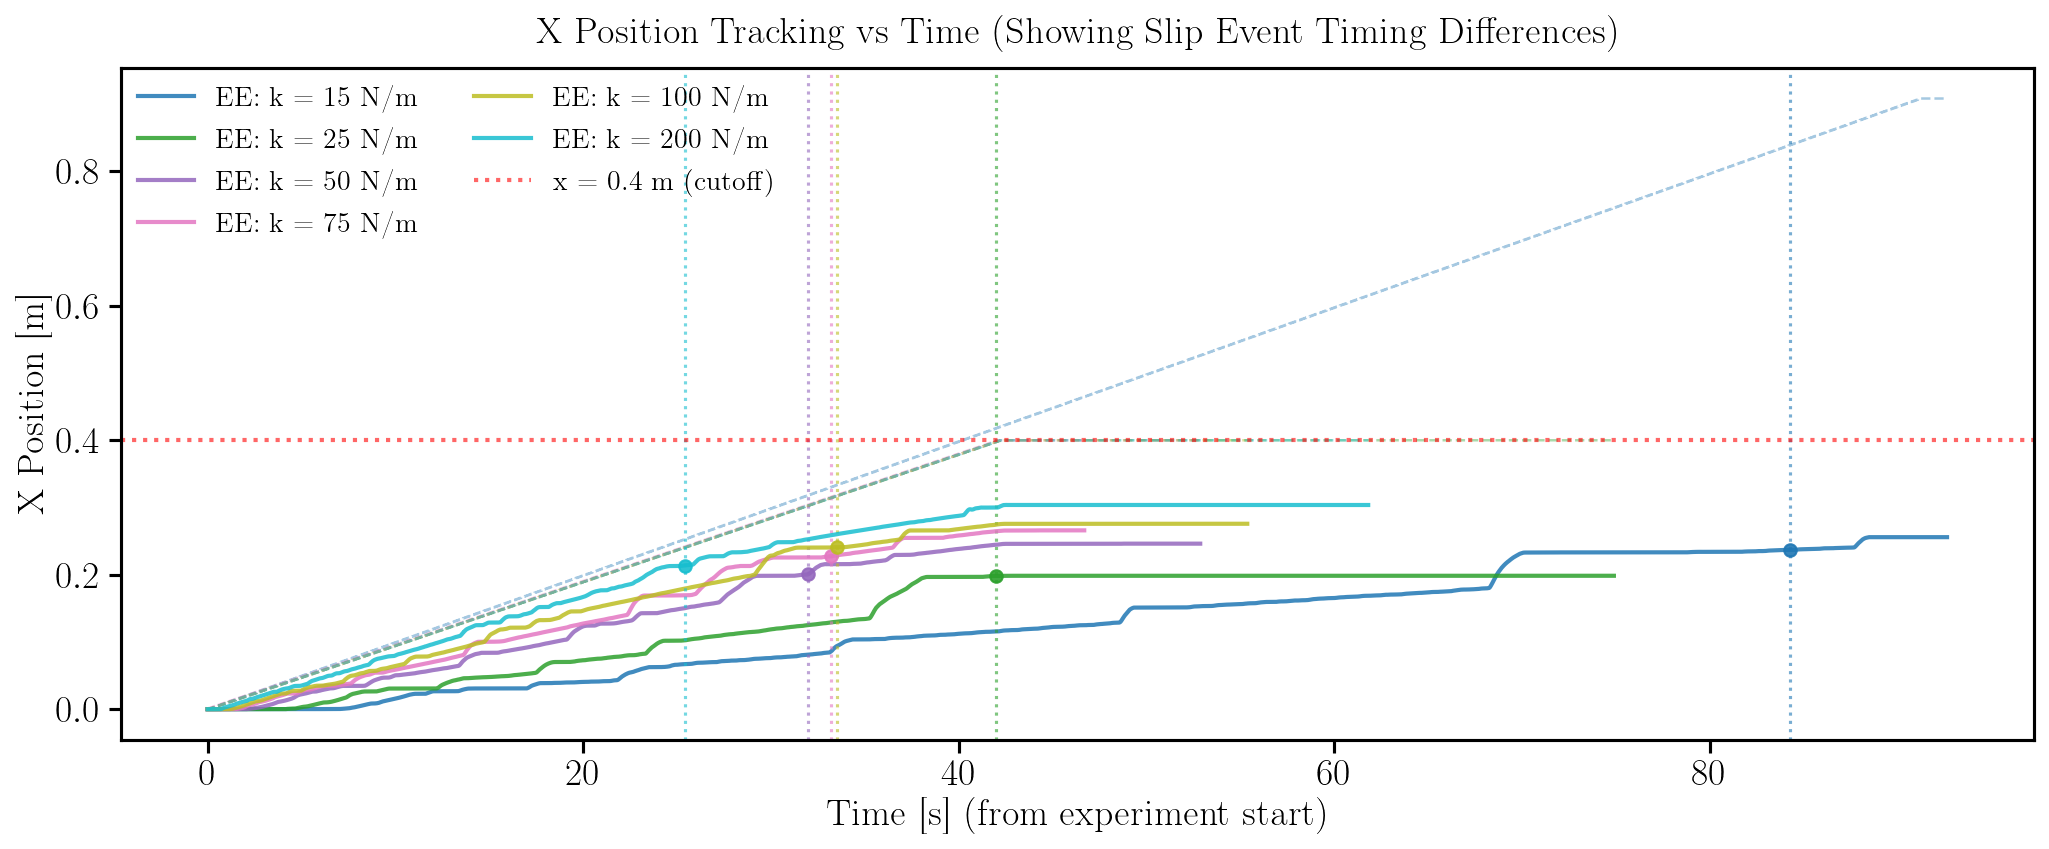


✓ X position plot complete
  Solid lines = end-effector x position
  Dashed lines = reference x position
  Vertical dashed lines (colored) = slip event time for each k


In [5]:
# Plot: X position vs Time comparison (showing time difference of slip events)
fig, ax = plt.subplots(figsize=(14, 6))

# Color map for k values
color_map = {k: colors[i] for i, k in enumerate(sorted(trajectories.keys()))}

# Plot x position vs time for each k (all starting at same t=0)
for k in sorted(trajectories.keys()):
    d = data[k]
    t = d['t']
    comp_pos = d['comp_pos']  # (n, N_VC, 3)
    goal = d['goal']          # (n, N_VC, 3)

    # Cut off at the same index as trajectories
    idx_cutoff = trajectories[k]['cutoff_idx']
    slip_idx = trajectories[k]['slip_event_idx']
    slip_time = t[slip_idx]
    
    t_cut = t[:idx_cutoff]
    t_rel = t_cut - t_cut[0]  # Relative time starting from 0 (not aligned to slip)

    ee_x = comp_pos[:idx_cutoff, 0, 0]  # End-effector x
    ref_x = goal[:idx_cutoff, 0, 0]     # Reference x

    # End-effector x position (solid)
    ax.plot(t_rel, ee_x,
            color=color_map[k], linewidth=2.0, alpha=0.85,
            label=f'EE: k = {k} N/m')

    # Reference x position (dashed, same color but lighter)
    ax.plot(t_rel, ref_x,
            '--', color=color_map[k], linewidth=1.2, alpha=0.4)
    
    # Mark slip event with vertical dashed line down to x-axis
    slip_time_rel = slip_time - t_cut[0]
    ax.axvline(x=slip_time_rel, color=color_map[k], linestyle=':', linewidth=1.5, alpha=0.6)
    # Mark point on the trajectory
    if slip_idx < idx_cutoff:
        ax.plot(slip_time_rel, ee_x[slip_idx], 'o', color=color_map[k], markersize=6, alpha=0.9, zorder=4)

# Cutoff line at x = 0.4
ax.axhline(y=0.4, color='red', linestyle=':', linewidth=2.0, alpha=0.6, label='x = 0.4 m (cutoff)')

ax.set_xlabel('Time [s] (from experiment start)')
ax.set_ylabel('X Position [m]')
ax.set_title('X Position Tracking vs Time (Showing Slip Event Timing Differences)')
ax.legend(loc='best', framealpha=0.95, ncol=2)
ax.grid(GRID)

plt.tight_layout()
plt.savefig(os.path.join('outputs', 'surface_tracking', 'x_position_vs_time.pdf'))
plt.show()

print("\n✓ X position plot complete")
print("  Solid lines = end-effector x position")
print("  Dashed lines = reference x position")
print("  Vertical dashed lines (colored) = slip event time for each k")

In [6]:
# Summary statistics
print("\n=== TRAJECTORY STATISTICS ===")
print(f"{'k':>5} | {'Duration':>10} | {'EE x-range':>15} | {'EE y-range':>15} | {'Max y-dev':>11}")
print("-" * 78)

for k in sorted(trajectories.keys()):
    traj = trajectories[k]
    ee_xy = traj['ee_xy']
    ref_xy = traj['ref_xy']
    
    x_range = (ee_xy[:, 0].min(), ee_xy[:, 0].max())
    y_range = (ee_xy[:, 1].min(), ee_xy[:, 1].max())
    
    # Max deviation from reference in y
    y_error = np.abs(ee_xy[:, 1] - ref_xy[:, 1])
    max_y_dev = np.max(y_error)
    
    print(f"{k:>5} | {traj['duration']:>10.2f}s | "
          f"[{x_range[0]:>6.3f}, {x_range[1]:>6.3f}] | "
          f"[{y_range[0]:>6.3f}, {y_range[1]:>6.3f}] | "
          f"{max_y_dev:>11.4f}")


=== TRAJECTORY STATISTICS ===
    k |   Duration |      EE x-range |      EE y-range |   Max y-dev
------------------------------------------------------------------------------
   15 |      92.65s | [-0.000,  0.256] | [-0.002,  0.003] |      0.0030
   25 |      74.90s | [-0.000,  0.198] | [-0.001,  0.002] |      0.0022
   50 |      52.87s | [-0.000,  0.246] | [-0.002,  0.001] |      0.0025
   75 |      46.69s | [ 0.000,  0.266] | [-0.002,  0.001] |      0.0023
  100 |      55.38s | [-0.000,  0.276] | [-0.001,  0.003] |      0.0027
  200 |      61.82s | [-0.000,  0.304] | [-0.001,  0.001] |      0.0010


k=25: Energy (0-45s) = 7.95 N·m·s
k=200: Energy (0-45s) = 11.42 N·m·s


/tmp/ipykernel_12504/4099854083.py:88: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.96])


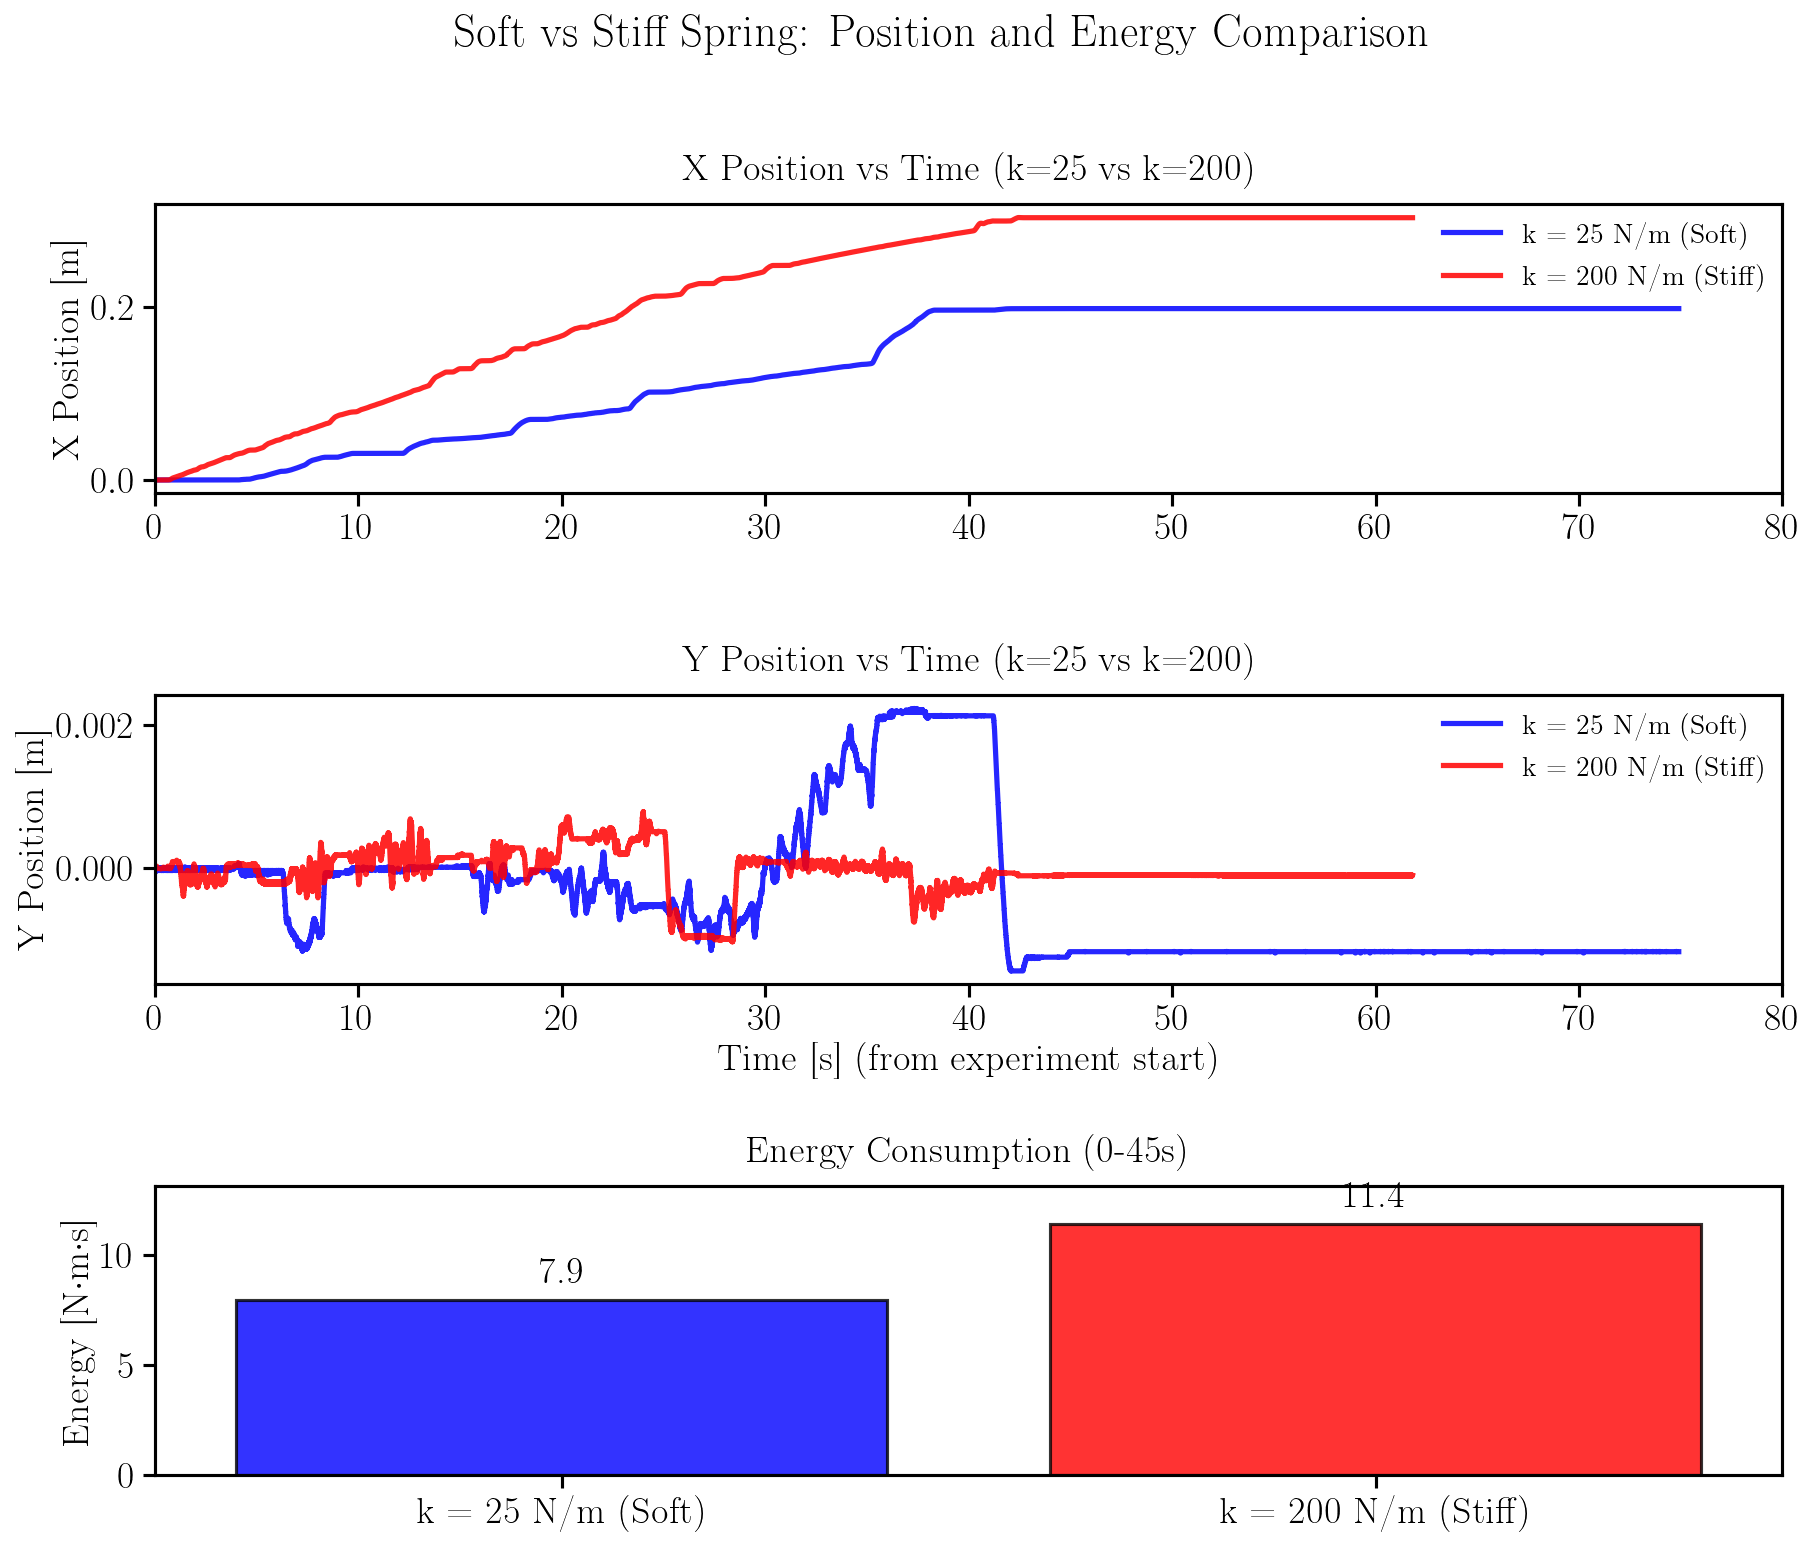


✓ k=25 vs k=200 comparison complete
  Energy ratio (k=200/k=25): 1.44x


In [7]:
# ═══════════════════════════════════════════════════════════════════════════════
# COMPARISON: k=25 vs k=200 (Soft vs Stiff)
# ═══════════════════════════════════════════════════════════════════════════════
from scipy.integrate import trapezoid as trapz

fig = plt.figure(figsize=(14, 11))
gs = fig.add_gridspec(3, 1, hspace=0.7)
ax_x = fig.add_subplot(gs[0])
ax_y = fig.add_subplot(gs[1])
ax_energy = fig.add_subplot(gs[2])

k_compare = [25, 200]
colors_compare = ['blue', 'red']
labels_compare = ['k = 25 N/m (Soft)', 'k = 200 N/m (Stiff)']

energy_values = {}

for k, color, label in zip(k_compare, colors_compare, labels_compare):
    d = data[k]
    t = d['t']
    comp_pos = d['comp_pos']
    goal = d['goal']
    tau = d['tau']  # Shape: (n, 9)
    
    # Get all data
    ee_x = comp_pos[:, 0, 0]
    ee_y = comp_pos[:, 0, 1]
    
    # Convert time to relative
    t_rel = t - t[0]
    
    # Plot X position
    ax_x.plot(t_rel, ee_x, linewidth=2.5, color=color, alpha=0.85, label=label)
    
    # Plot Y position
    ax_y.plot(t_rel, ee_y, linewidth=2.5, color=color, alpha=0.85, label=label)
    
    # Calculate energy: integral of |tau| from t=0 to t=45s
    idx_45s = np.searchsorted(t_rel, 45.0)
    t_window = t_rel[:idx_45s]
    tau_window = tau[:idx_45s, :]  # All motors
    
    # Energy = integral of sum(|tau|) over time
    # Using trapezoidal integration
    tau_magnitude = np.sum(np.abs(tau_window), axis=1)  # Sum |tau| across all 9 motors
    energy = trapz(tau_magnitude, t_window)
    energy_values[k] = energy
    
    print(f"k={k}: Energy (0-45s) = {energy:.2f} N·m·s")

# Format X position plot
ax_x.set_ylabel('X Position [m]')
ax_x.set_title('X Position vs Time (k=25 vs k=200)')
ax_x.grid(GRID)
ax_x.legend(loc='best')
ax_x.set_xlim(0, 80)

# Format Y position plot
ax_y.set_ylabel('Y Position [m]')
ax_y.set_title('Y Position vs Time (k=25 vs k=200)')
ax_y.grid(GRID)
ax_y.legend(loc='best')
ax_y.set_xlim(0, 80)

# Energy comparison bar plot
ax_energy.bar(range(len(k_compare)), [energy_values[k] for k in k_compare], 
              color=colors_compare, alpha=0.8, edgecolor='black', linewidth=1.5)
ax_energy.set_xticks(range(len(k_compare)))
ax_energy.set_xticklabels(labels_compare)
ax_energy.set_ylabel('Energy [N·m·s]')
ax_energy.set_title('Energy Consumption (0-45s)')
ax_energy.grid(GRID, axis='y')

# Add value labels on bars with more space
max_energy = max(energy_values.values())
ax_energy.set_ylim(0, max_energy * 1.15)  # Add 15% padding at top

for i, k in enumerate(k_compare):
    ax_energy.text(i, energy_values[k] + max_energy*0.04, 
                   f'{energy_values[k]:.1f}', ha='center', va='bottom')

ax_energy.set_xlim(-0.5, len(k_compare) - 0.5)

# Set common x-label
ax_y.set_xlabel('Time [s] (from experiment start)')

fig.suptitle('Soft vs Stiff Spring: Position and Energy Comparison', y=0.995)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join('outputs', 'surface_tracking', 'soft_vs_stiff_comparison.pdf'))
plt.show()

print("\n✓ k=25 vs k=200 comparison complete")
print(f"  Energy ratio (k=200/k=25): {energy_values[200]/energy_values[25]:.2f}x")

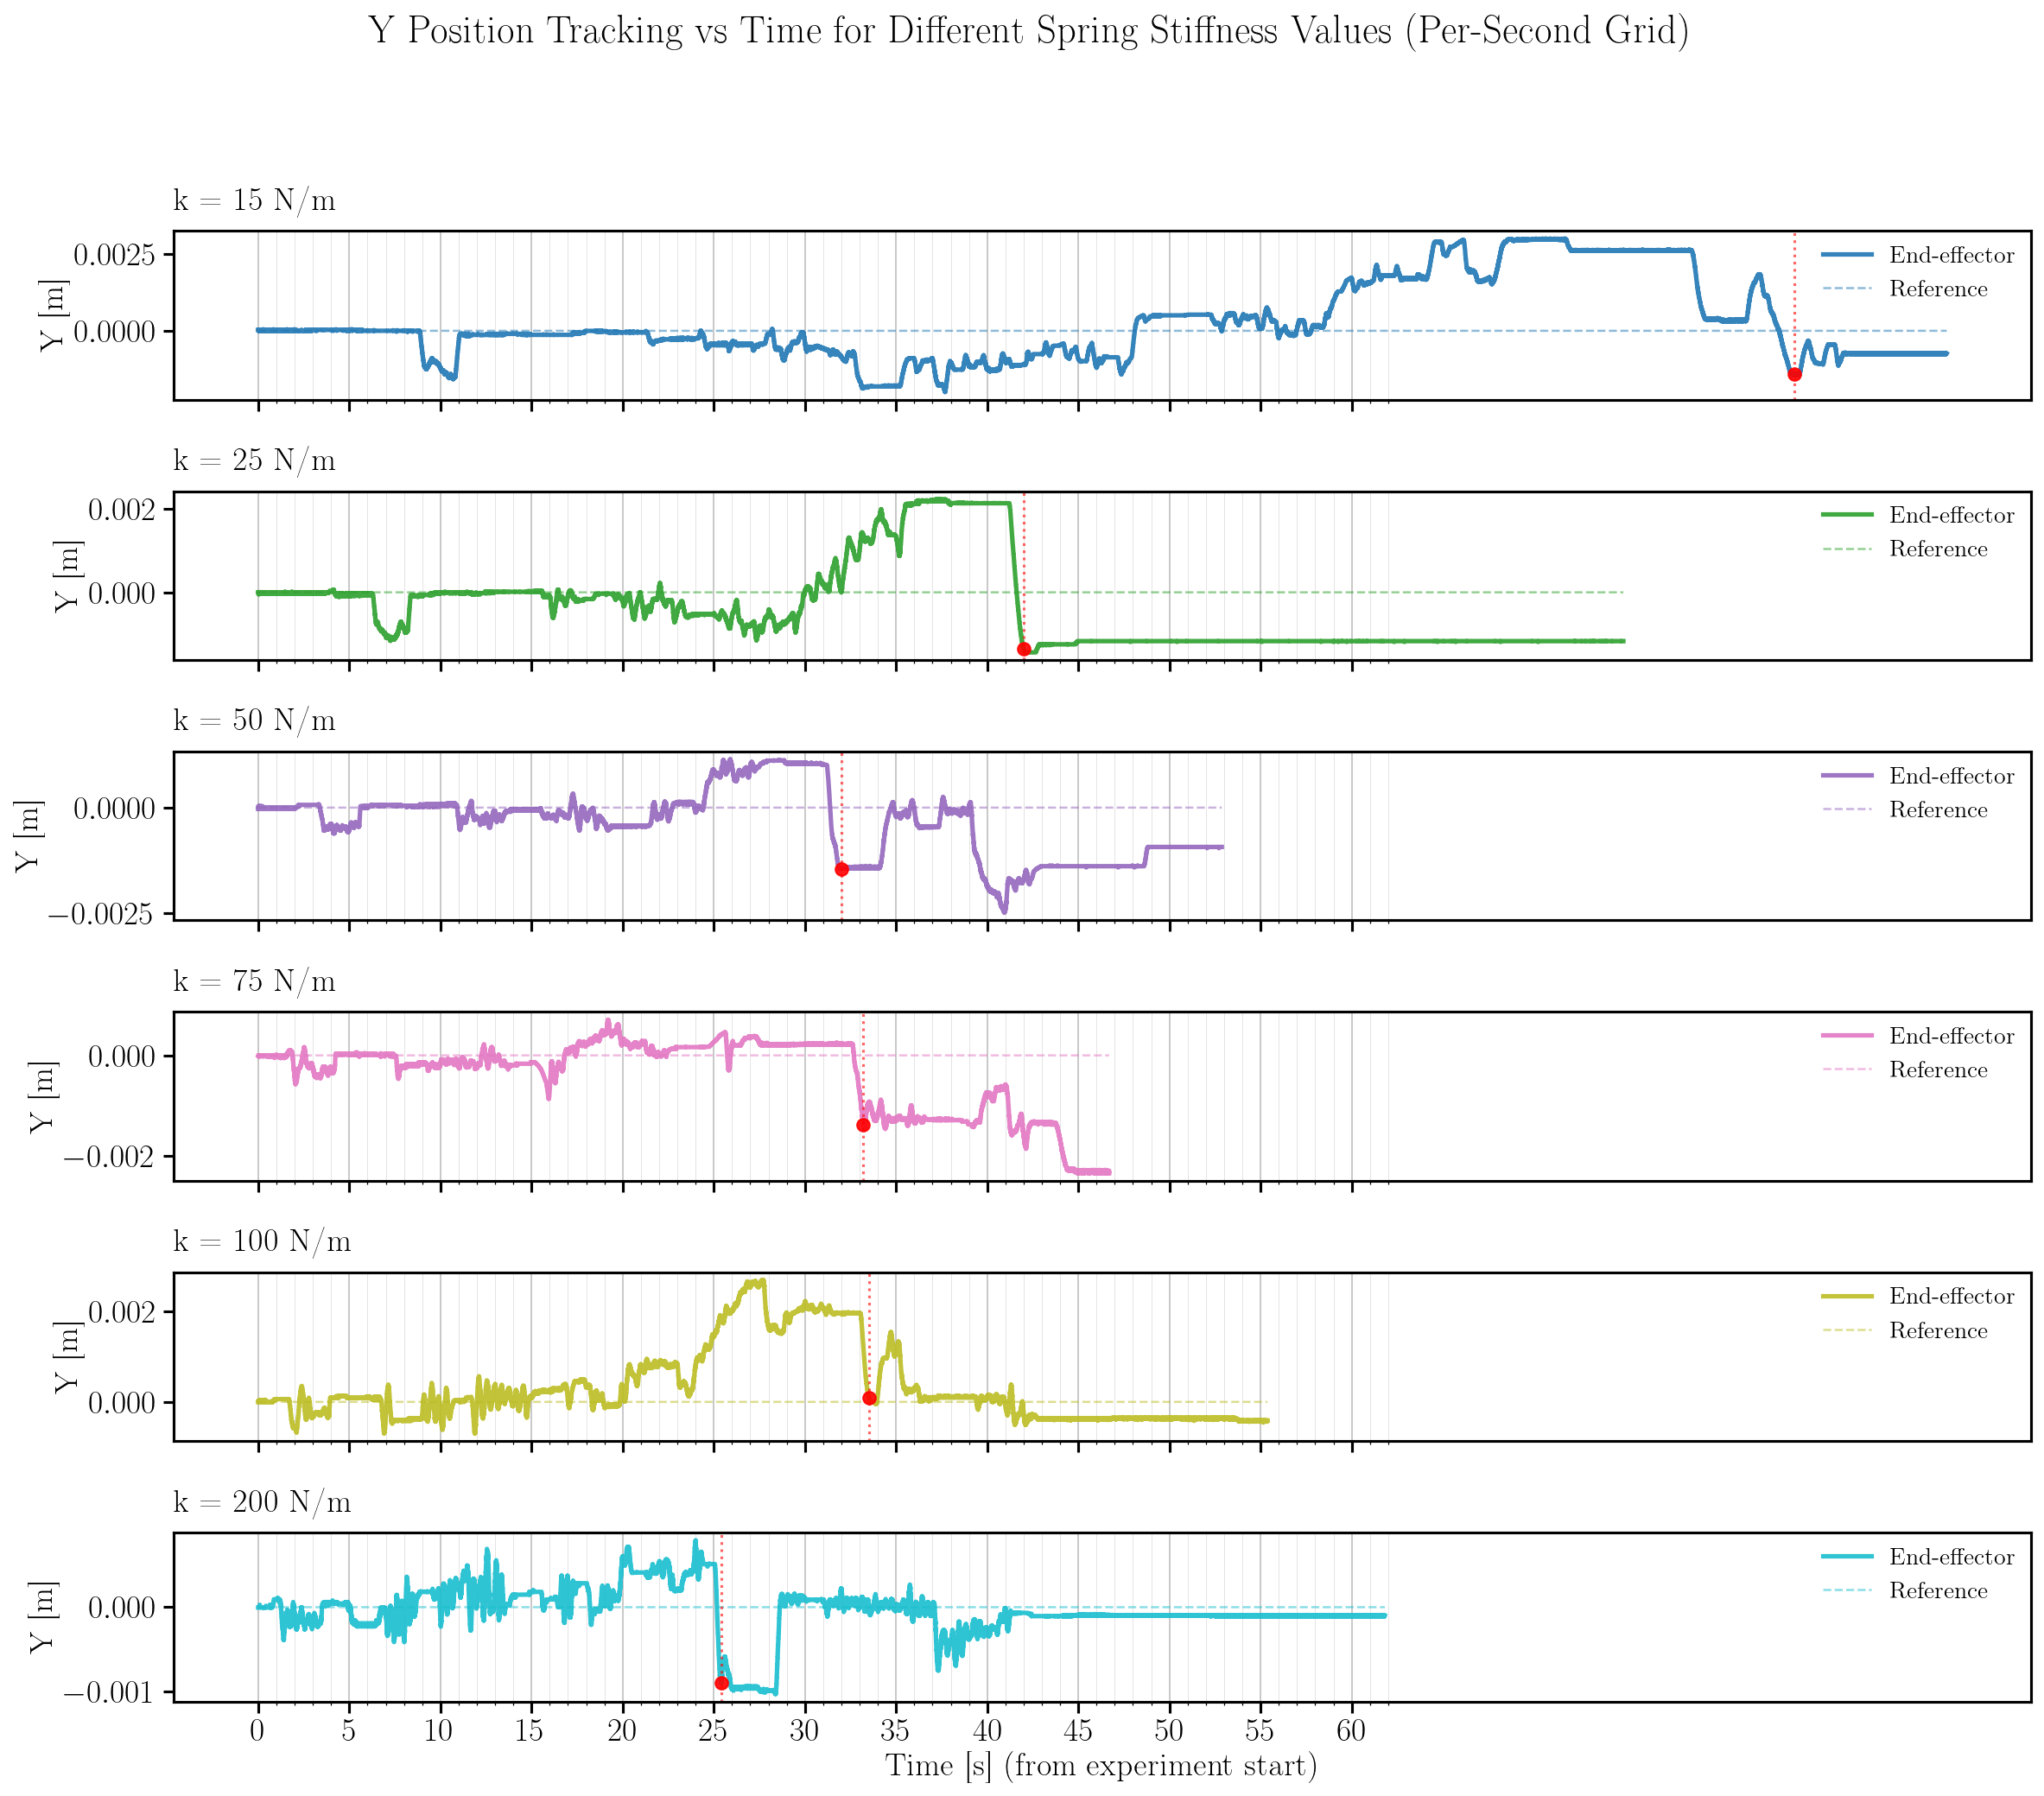


✓ Y position subplots complete (with per-second time grid)
  Solid lines = end-effector y position
  Dashed lines = reference y position
  Red dashed vertical lines + circles = slip event
  Major gridlines = 1-second intervals (vertical lines)


In [8]:
# Plot: Y position vs Time for each k (6 separate subplots vertically stacked)
fig, axes = plt.subplots(6, 1, figsize=(16, 14), sharex=True)

# Color map for k values
color_map = {k: colors[i] for i, k in enumerate(sorted(trajectories.keys()))}
k_list = sorted(trajectories.keys())

for idx, k in enumerate(k_list):
    ax = axes[idx]
    
    d = data[k]
    t = d['t']
    comp_pos = d['comp_pos']  # (n, N_VC, 3)
    goal = d['goal']          # (n, N_VC, 3)

    # Cut off at the same index as trajectories
    idx_cutoff = trajectories[k]['cutoff_idx']
    slip_idx = trajectories[k]['slip_event_idx']
    slip_time = trajectories[k]['slip_time']
    
    t_cut = t[:idx_cutoff]
    t_rel = t_cut - t_cut[0]  # Relative time starting from 0

    ee_y = comp_pos[:idx_cutoff, 0, 1]  # End-effector y
    ref_y = goal[:idx_cutoff, 0, 1]     # Reference y

    # End-effector y position (solid, thicker)
    ax.plot(t_rel, ee_y,
            color=color_map[k], linewidth=2.5, alpha=0.9,
            label='End-effector')

    # Reference y position (dashed, thinner)
    ax.plot(t_rel, ref_y,
            '--', color=color_map[k], linewidth=1.2, alpha=0.5,
            label='Reference')
    
    # Mark slip event with vertical dashed line
    slip_time_rel = slip_time
    ax.axvline(x=slip_time_rel, color='red', linestyle=':', linewidth=1.5, alpha=0.6)
    
    # Mark point on trajectory
    if slip_idx < idx_cutoff:
        ax.plot(slip_time_rel, ee_y[slip_idx], 'ro', markersize=7, alpha=0.9, zorder=4)

    ax.set_ylabel('Y [m]')
    ax.set_title(f'k = {k} N/m', loc='left')
    
    # Per-second fine gridlines (unlabeled) + labeled ticks every 5s to avoid
    # crowding/overlapping tick labels on the shared bottom x-axis.
    max_time = t_rel[-1]
    ax.set_xticks(np.arange(0, int(max_time) + 2, 5), minor=False)
    ax.set_xticks(np.arange(0, int(max_time) + 2, 1), minor=True)
    ax.grid(True, which='major', axis='x', linestyle='-', linewidth=0.8, alpha=0.5, color='gray')
    ax.grid(True, which='minor', axis='x', linestyle='-', linewidth=0.4, alpha=0.25, color='gray')
    ax.grid(True, which='minor', axis='y', linestyle=':', linewidth=0.4, alpha=0.2)
    
    ax.legend(loc='upper right')

axes[-1].set_xlabel('Time [s] (from experiment start)')
fig.suptitle('Y Position Tracking vs Time for Different Spring Stiffness Values (Per-Second Grid)', y=0.995)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.savefig(os.path.join('outputs', 'surface_tracking', 'y_position_all_k.pdf'))
plt.show()

print("\n✓ Y position subplots complete (with per-second time grid)")
print("  Solid lines = end-effector y position")
print("  Dashed lines = reference y position")
print("  Red dashed vertical lines + circles = slip event")
print("  Major gridlines = 1-second intervals (vertical lines)")